<a href="https://colab.research.google.com/github/sancheznaranjoyairchayanne-design/tecnm-desarrollo-web/blob/main/laboratorios/sesion03/sesion03_laboratorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 Sesión 03 · Headers, Content-Type y Negociación de Contenido

**Desarrollo de Aplicaciones Web (DAB-2201)** · TecNM Cancún  
**Docente:** MCC. Iván Márquez Larios (`ijmarquezl`)  
**Repositorio:** https://github.com/ijmarquezl/tecnm-desarrollo-web

> **La pregunta de hoy:** ¿Cómo sabe el servidor qué formato le estás enviando? = El servidor sabe qué formato le estoy enviando porque el cliente lo indica mediante el encabezado HTTP Content-Type. Este encabezado especifica cómo está codificado el cuerpo de la solicitud, por ejemplo application/json o text/plain. Además, el encabezado Accept permite indicar qué formato de respuesta puede recibir el cliente.

---

## 🖥️ Así se verá el resultado final

```http
$ curl -X POST http://127.0.0.1:8000/api/libros \
       -H "Content-Type: application/json" \
       -H "Accept: application/json" \
       -d '{"titulo":"Rayuela","anio":1963}'
HTTP/1.1 201 Created
content-type: application/json
{"id":1,"titulo":"Rayuela","anio":1963}

$ curl -X POST http://127.0.0.1:8000/api/libros \
       -H "Content-Type: text/plain" \
       -d 'Rayuela'
HTTP/1.1 415 Unsupported Media Type

$ curl http://127.0.0.1:8000/api/libros \
       -H "Accept: application/xml"
HTTP/1.1 406 Not Acceptable
```

_El navegador envía Accept por ti; una herramienta como curl te obliga a ser explícito._

**No hay pasos intermedios.** El cuaderno declara el resultado que debe existir al final; tú decides la estructura, los modelos y el orden de tu implementación. La celda de verificación compara tu resultado con este contrato.

---

## 🎯 Al finalizar podrás

- Leer y emitir encabezados HTTP correctamente.
- Diferenciar Content-Type (lo que envío) de Accept (lo que acepto).
- Rechazar formatos no soportados con 415 y 406.

## ✅ Criterios de aceptación

El verificador ejecutará estos casos. Cada uno debe quedar en verde:

- [ ] POST válido en JSON → HTTP 201
- [ ] POST en texto plano se rechaza con 415 → HTTP 415
- [ ] GET que pide XML se rechaza con 406 → HTTP 406
- [ ] GET que acepta JSON responde 200 → HTTP 200

## 🧩 El reto

Implementa la creación y el listado de libros, pero haz que la API negocie el formato de entrada y de salida.

**Requisitos del contrato**

- POST /api/libros solo acepta Content-Type: application/json; si no, responde 415.
- GET /api/libros solo responde si el cliente acepta application/json; si pide XML, responde 406.
- Las respuestas correctas llevan Content-Type: application/json.
- Un POST válido responde 201 con el libro creado.

> **Pista conceptual:** Puedes inspeccionar `request.headers` dentro de una dependencia o middleware antes de que se procese el cuerpo. El formato no se adivina: se declara.

## 📦 Entregable

Cuaderno con los cuatro casos en verde y bitácora `auditorias/auditoria_sesion03.md`.


## ⚙️ Preparación del entorno

Ejecuta esta celda una sola vez. Instala las herramientas del track **Python / FastAPI** y descarga el motor de verificación del repositorio. No necesitas instalar nada en tu computadora: todo corre en Colab.


In [3]:
import os, sys

print("⏳ Preparando el entorno de Desarrollo Web...")

!pip install -q fastapi uvicorn httpx pydantic "passlib[bcrypt]" bcrypt python-jose[cryptography] PyJWT "sqlalchemy[asyncio]" greenlet aiosqlite alembic python-multipart

!wget -q -O verificar.py https://raw.githubusercontent.com/ijmarquezl/tecnm-desarrollo-web/c275993ba69ef2a8cf650b2f127b55c8356279d7/laboratorios/verificar.py

if not os.path.exists("verificar.py") or os.path.getsize("verificar.py") < 1000:
    raise RuntimeError(
        "No se pudo descargar verificar.py. Revisa tu conexión o abre el cuaderno desde el repositorio del curso."
    )

print("✅ Entorno listo")
print("Python:", sys.version.split()[0])
print("Motor de verificación:", os.path.getsize("verificar.py"), "bytes")


⏳ Preparando el entorno de Desarrollo Web...
✅ Entorno listo
Python: 3.13.18
Motor de verificación: 13395 bytes


## 🧩 El reto: escribe el resultado

Crea el o los archivos del contrato. No hay una plantilla de pasos: el esqueleto solo te da el punto de partida. Todo lo que sigue lo decides tú.

**Archivos que debes producir:** `app.py`


### 📄 `app.py`

Archivo principal de la implementación.

In [5]:
%%writefile app.py

from fastapi import FastAPI, Request
from fastapi.responses import JSONResponse
from pydantic import BaseModel

app = FastAPI(title="API Libros")

libros = []


class Libro(BaseModel):
    titulo: str
    anio: int


@app.middleware("http")
async def negociar(request: Request, call_next):

    if request.url.path == "/api/libros" and request.method == "POST":
        tipo = request.headers.get("content-type", "").split(";")[0]

        if tipo != "application/json":
            return JSONResponse(
                {"detail": "Usa JSON"},
                status_code=415
            )

    if request.url.path == "/api/libros" and request.method == "GET":
        accept = request.headers.get("accept", "*/*")

        if "application/xml" in accept and "application/json" not in accept:
            return JSONResponse(
                {"detail": "No aceptable"},
                status_code=406
            )

    return await call_next(request)


@app.post("/api/libros", status_code=201)
async def crear_libro(libro: Libro):

    nuevo = {
        "id": len(libros) + 1,
        "titulo": libro.titulo,
        "anio": libro.anio
    }

    libros.append(nuevo)
    return nuevo


@app.get("/api/libros")
async def listar_libros():
    return libros


Overwriting app.py


## 🧪 Tu contrato C-R-E-O

Antes de pedir ayuda a la IA, escribe el contrato que describe el resultado. Esto alimenta tu bitácora y te obliga a pensar como arquitecto:

| Elemento | Tu definición |
| :--- | :--- |
| **Contexto** | Framework, versión y restricciones del entorno. |
| **Rol** | Qué papel técnico debe asumir el modelo. |
| **Especificación** | Rutas, entradas, salidas, validaciones y códigos HTTP. |
| **Output** | Qué formato exacto esperas de vuelta. |

> No pegues código de la IA sin auditarlo. La responsabilidad técnica del resultado es tuya.


## 🔍 Verificación del resultado

Ejecuta esta celda cuando tu implementación esté lista. La verificación no modifica tu código: solo observa el comportamiento y compara con el contrato. Si algo falla, el mensaje te dice **qué esperaba** y **qué recibió**.


In [6]:
from verificar import probar_http

casos = [{'descripcion': 'POST válido en JSON',
  'metodo': 'POST',
  'ruta': '/api/libros',
  'headers': {'Content-Type': 'application/json', 'Accept': 'application/json'},
  'json': {'titulo': 'Rayuela', 'anio': 1963},
  'estado': 201,
  'json_contiene': {'id': 1, 'titulo': 'Rayuela', 'anio': 1963},
  'headers_contiene': {'content-type': 'application/json'}},
 {'descripcion': 'POST en texto plano se rechaza con 415',
  'metodo': 'POST',
  'ruta': '/api/libros',
  'content': 'Rayuela',
  'headers': {'Content-Type': 'text/plain'},
  'estado': 415},
 {'descripcion': 'GET que pide XML se rechaza con 406',
  'metodo': 'GET',
  'ruta': '/api/libros',
  'headers': {'Accept': 'application/xml'},
  'estado': 406},
 {'descripcion': 'GET que acepta JSON responde 200',
  'metodo': 'GET',
  'ruta': '/api/libros',
  'headers': {'Accept': 'application/json'},
  'estado': 200,
  'headers_contiene': {'content-type': 'application/json'}}]

probar_http(casos, archivo="app.py", limpiar=[], env={})


VERIFICACIÓN DEL RESULTADO · 4 casos · app.py
✅ 01. POST válido en JSON
✅ 02. POST en texto plano se rechaza con 415
✅ 03. GET que pide XML se rechaza con 406
✅ 04. GET que acepta JSON responde 200
------------------------------------------------------------------------------
RESULTADO: 4/4 casos correctos. ¡Resultado logrado!


## 📝 Cierre y bitácora

1. Copia la plantilla `plantillas/auditoria_sesion03.md` a `auditorias/auditoria_sesion03.md` en tu fork.
2. Responde con tus palabras:
   - ¿Qué resultado te costó más alcanzar y por qué? = El resultado que más me costó alcanzar fue el rechazo de solicitudes con el código HTTP 406. Al principio entendía cómo validar el encabezado Content-Type, pero me resultó más difícil comprender cuándo debía utilizarse el encabezado Accept para determinar si el cliente podía recibir el formato de respuesta ofrecido por la API.

   - ¿Qué decisión de diseño tomaste que no estaba escrita en el contrato? = Decidí implementar la validación de los encabezados HTTP mediante un middleware. De esta forma, la lógica de validación queda centralizada y separada de las rutas, lo que facilita el mantenimiento y la reutilización del código.

   - ¿Qué error detectó la verificación que tú no habías previsto? = La verificación detectó que no estaba rechazando correctamente las peticiones con Content-Type diferente de application/json. Inicialmente asumí que FastAPI gestionaría automáticamente esta validación, pero fue necesario implementarla explícitamente para devolver el código HTTP 415 cuando el formato enviado no era compatible.

3. Haz commit de tu cuaderno ejecutado y de tu bitácora.-git add app.py auditorias/auditoria_sesion03.md sesion03_laboratorio.ipynb
git commit -m "Completa sesion 03: Content-Type y negociacion de contenido"
git push origin main

**La sesión termina cuando el resultado está en verde, no cuando el código "parece funcionar".**
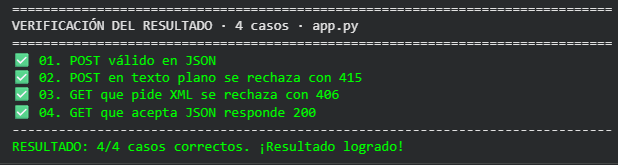